# Unknown-appliance detection with a GRU autoencoder on UK-DALE

This notebook trains a **GRU sequence-to-sequence autoencoder (GRU-AE)** on a synthetic aggregate built from *known* appliances only, then checks whether it can flag a **novel appliance** injected into the aggregate through its reconstruction error.

It follows exactly the same protocol as the USAD notebook of this repository (`usad_nilm_novelty_detection.ipynb`); only the model of step 4 changes, so the results are directly comparable across autoencoders.

**Protocol**

1. **Dataset**: UK-DALE, House 1, read with NILMTK.
2. **Synthetic aggregate**: sum the ground-truth power of the *known* appliances only (never the real house mains).
3. **Windowing**: sliding windows (`WINDOW_SIZE`, `STEP`) with z-score normalization fitted on training windows.
4. **Training**: a GRU-AE with a single decoder and a single MSE reconstruction loss (no adversarial second decoder). This isolates the architecture family, recurrent versus USAD's dense dual decoder, as the benchmark variable.
5. **Scoring**: per-window reconstruction error `MSE(w, recon(w))` is the anomaly score, as in the USAD notebook.
6. **Progressive test**: inject one novel appliance at a time (low power, then high power) into a held-out period, report ROC-AUC and PR-AUC, and derive two operating thresholds (ROC / Youden's J and F1-optimal) from the labeled test windows. A sequential per-period evaluation follows.

**Setup**

- Requires UK-DALE converted to HDF5 for NILMTK (`ukdale.h5`). Set its location with the `UKDALE_H5_PATH` environment variable or in the configuration cell.
- `nilmtk` is installed from GitHub in the first code cell. PyTorch, NumPy, pandas, scikit-learn and matplotlib are also needed.
- A GPU speeds up training but is optional.
- On Kaggle: attach the dataset, turn Internet on, and optionally enable a GPU.

See the **Results and limitations** section at the end before reusing the numbers.

## 1. Install dependencies

Only `nilmtk` and `nilm_metadata` are needed to read UK-DALE; they are installed from GitHub without their pinned dependencies.

In [ ]:
!pip install -q --no-deps git+https://github.com/nilmtk/nilm_metadata.git
!pip install -q --no-deps git+https://github.com/nilmtk/nilmtk.git

## 2. Imports

In [ ]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from matplotlib.patches import Patch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import (
    accuracy_score, average_precision_score, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)

from nilmtk import DataSet

## 3. Configuration

Keep the `TRAIN` and `TEST` periods **non-overlapping** to avoid leakage between training and evaluation.

In [ ]:
# ----------------------------
# Dataset / windowing config
# ----------------------------
_KAGGLE_PATH  = "/kaggle/input/datasets/abdelmdz/uk-dale/ukdale.h5"
UKDALE_H5_PATH = os.environ.get(
    "UKDALE_H5_PATH",
    _KAGGLE_PATH if os.path.exists(_KAGGLE_PATH) else "data/ukdale.h5",
)
BUILDING       = 1
SAMPLE_PERIOD  = 6              # seconds
WINDOW_SIZE    = 200          # samples per window (must be divisible by 4)
STEP           = 5              # sliding-window stride, in samples
BATCH_SIZE     = 1024
EPOCHS         = 50
VAL_FRACTION   = 0.15
RANDOM_SEED    = 42

# ----------------------------
# ON thresholds (Watts), used to build ground-truth "appliance is ON" labels.
# These are hand-chosen heuristics, not tuned values.
# ----------------------------
ON_THRESHOLDS = {
    "fridge freezer":  50,
    "washing machine": 20,
    "dish washer":     20,
    "kettle":          2000,
    "microwave":       200,
}

# ----------------------------
# Known appliances: summed together to build the synthetic aggregate
# the AE is trained on (protocol step 2).
# ----------------------------
KNOWN_APPLIANCES = [
    "fridge freezer",
    "washing machine",
    "dish washer",
]

# ----------------------------
# Novel / unknown appliances, one per difficulty level (protocol step 6).
# Must NOT be in KNOWN_APPLIANCES.
# ----------------------------
NEW_APPLIANCE_LEVELS = {
    "low":    "microwave",   # small contribution -> hardest case
    "high":   "kettle",      # large power spike -> easiest case
}

# ----------------------------
# Time periods -- adjust to the real coverage of your ukdale.h5.
# ----------------------------
TRAIN_START = "2013-04-01"
TRAIN_END   = "2014-05-31"

TEST_START  = "2014-07-01"     # progressive novel-appliance injection (step 6)
TEST_END    = "2014-08-31"

OUTPUT_DIR = os.environ.get("OUTPUT_DIR", "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)

## 4. Device utilities

In [7]:
def get_default_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    return torch.device('cpu')


def to_device(data, device):
    if isinstance(data, (list, tuple)):
        return [to_device(x, device) for x in data]
    return data.to(device, non_blocking=True)


class DeviceDataLoader:
    """Wrap a DataLoader to move batches to the chosen device on the fly."""
    def __init__(self, dl, device):
        self.dl = dl
        self.device = device

    def __iter__(self):
        for b in self.dl:
            yield to_device(b, self.device)

    def __len__(self):
        return len(self.dl)


device = get_default_device()
print("Using device:", device)

Using device: cuda


## 5. Model (GRU-AE)

A GRU **encoder** reads the window step-by-step and compresses it into a single latent
vector (its final hidden state, projected to `z_size`). A GRU **decoder** takes that latent
vector (repeated at every time step as input) and reconstructs the full window.

Unlike USAD, there is a single decoder and a single MSE reconstruction loss -- no
adversarial training. The anomaly score (protocol step 5) is simply the per-window
reconstruction MSE, `mean((w - recon(w))**2)`, so it is directly comparable to USAD's
combined score and to the VAE notebook's score.

In [ ]:
class GRUEncoder(nn.Module):
    """Reads the window step-by-step; the final hidden state is projected to the latent vector."""
    def __init__(self, hidden_size, latent_size, num_layers=1):
        super().__init__()
        self.gru = nn.GRU(input_size=1, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
        self.to_latent = nn.Linear(hidden_size, latent_size)

    def forward(self, w):
        # w: (batch, seq_len) -> (batch, seq_len, 1)
        x = w.unsqueeze(-1)
        _, h_n = self.gru(x)          # h_n: (num_layers, batch, hidden_size)
        h_last = h_n[-1]              # (batch, hidden_size)
        z = self.to_latent(h_last)    # (batch, latent_size)
        return z


class GRUDecoder(nn.Module):
    """Repeats the latent vector at every time step as GRU input; a linear head projects
    each GRU output back to a scalar power value."""
    def __init__(self, latent_size, hidden_size, seq_len, num_layers=1):
        super().__init__()
        self.seq_len = seq_len
        self.latent_to_hidden = nn.Linear(latent_size, hidden_size)
        self.gru = nn.GRU(input_size=latent_size, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
        self.to_output = nn.Linear(hidden_size, 1)

    def forward(self, z):
        z_seq = z.unsqueeze(1).repeat(1, self.seq_len, 1)          # (batch, seq_len, latent_size)
        h0 = torch.tanh(self.latent_to_hidden(z)).unsqueeze(0)     # (1, batch, hidden_size)
        out, _ = self.gru(z_seq, h0)
        recon = self.to_output(out).squeeze(-1)                    # (batch, seq_len)
        return recon


class GruAeModel(nn.Module):
    def __init__(self, w_size, z_size, hidden_size=64, num_layers=1):
        super().__init__()
        self.w_size = w_size
        self.encoder = GRUEncoder(hidden_size, z_size, num_layers)
        self.decoder = GRUDecoder(z_size, hidden_size, w_size, num_layers)

    def forward(self, w):
        z = self.encoder(w)
        recon = self.decoder(z)
        return recon

    def training_step(self, batch):
        recon = self(batch)
        return torch.mean((batch - recon) ** 2)

    def validation_step(self, batch):
        with torch.no_grad():
            recon = self(batch)
            loss = torch.mean((batch - recon) ** 2)
        return {"val_loss": loss}


def evaluate(model, val_loader):
    outputs = [model.validation_step(to_device(batch, device)) for [batch] in val_loader]
    val_loss = torch.stack([o["val_loss"] for o in outputs]).mean().item()
    return {"val_loss": val_loss}


def training(epochs, model, train_loader, val_loader, opt_func=torch.optim.Adam, lr=1e-3):
    history = []
    optimizer = opt_func(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train()
        train_losses = []
        for [batch] in train_loader:
            batch = to_device(batch, device)
            loss = model.training_step(batch)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            train_losses.append(loss.item())

        model.eval()
        result = evaluate(model, val_loader)
        result["train_loss"] = float(np.mean(train_losses))
        print("Epoch [{}], train_loss: {:.4f}, val_loss: {:.4f}".format(
            epoch, result["train_loss"], result["val_loss"]))
        history.append(result)
    return history


def compute_scores(model, loader):
    """Per-window anomaly score = reconstruction MSE (protocol step 5)."""
    model.eval()
    scores = []
    with torch.no_grad():
        for [batch] in loader:
            batch = to_device(batch, device)
            recon = model(batch)
            s = torch.mean((batch - recon) ** 2, axis=1)
            scores.append(s.cpu().numpy())
    return np.concatenate(scores) if scores else np.empty((0,))

## 6. Data utilities (protocol steps 2-3)

Build the synthetic aggregate from NILMTK ground truth, window it, and normalize.

In [ ]:
def _get_meter(dataset, building, appliance_name):
    elec = dataset.buildings[building].elec
    try:
        return elec[appliance_name]
    except KeyError:
        available = [m.label() for m in elec.submeters().meters]
        raise ValueError(
            f"Appliance '{appliance_name}' not found in building {building}. "
            f"Available submeters: {available}"
        )


def load_appliance_power(dataset, building, appliance_name, sample_period, start=None, end=None):
    """Return a single resampled, gap-filled power series (Watts) for one appliance."""
    dataset.set_window(start=start, end=end)
    meter = _get_meter(dataset, building, appliance_name)
    series = next(meter.power_series(sample_period=sample_period))
    series = series.resample(f"{sample_period}s").mean()
    series = series.fillna(0.0)
    series.name = appliance_name
    return series


def build_synthetic_aggregate(dataset, building, appliance_list, sample_period, start=None, end=None):
    """
    Protocol step 2: agregat_connu(t) = sum of ground-truth power of the chosen appliances.
    Returns a DataFrame with one column per appliance plus an 'aggregate' column.
    """
    series_dict = {}
    for name in appliance_list:
        series_dict[name] = load_appliance_power(dataset, building, name, sample_period, start, end)

    df = pd.concat(series_dict, axis=1)
    df = df.fillna(0.0)
    df["aggregate"] = df[appliance_list].sum(axis=1)
    return df


def make_windows(x, window_size, step):
    """Protocol step 3: sliding windows over a 1D array -> (n_windows, window_size)."""
    x = np.ascontiguousarray(x, dtype=np.float32)
    n = len(x)
    n_windows = (n - window_size) // step + 1
    if n_windows <= 0:
        return np.empty((0, window_size), dtype=np.float32)
    shape = (n_windows, window_size)
    strides = (x.strides[0] * step, x.strides[0])
    return np.lib.stride_tricks.as_strided(x, shape=shape, strides=strides).copy()


def make_window_labels(power_values, threshold, window_size, step):
    """Window is labeled 1 if the appliance is ON (power >= threshold) at ANY sample within it."""
    on = (np.asarray(power_values, dtype=np.float32) >= threshold).astype(np.float32)
    windows = make_windows(on, window_size, step)
    if len(windows) == 0:
        return np.empty((0,), dtype=np.int32)
    return (windows.max(axis=1) > 0).astype(np.int32)


class ZScoreScaler1D:
    """Global z-score (standard) scaler, fit on the training aggregate only."""
    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, x):
        self.mean_ = float(np.mean(x))
        self.std_ = float(np.std(x))
        if self.std_ < 1e-8:
            self.std_ = 1e-8
        return self

    def transform(self, x):
        return ((np.asarray(x, dtype=np.float32) - self.mean_) / self.std_).astype(np.float32)

    def inverse_transform(self, x):
        return (np.asarray(x, dtype=np.float32) * self.std_ + self.mean_).astype(np.float32)

    def fit_transform(self, x):
        self.fit(x)
        return self.transform(x)

## 7. Load UK-DALE and build the known-only training aggregate

In [10]:
def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(RANDOM_SEED)

dataset = DataSet(UKDALE_H5_PATH)

df_train = build_synthetic_aggregate(
    dataset, BUILDING, KNOWN_APPLIANCES, SAMPLE_PERIOD,
    start=TRAIN_START, end=TRAIN_END,
)
agg = df_train["aggregate"].values.astype(np.float32)
print("Known-only aggregate length:", len(agg))

Known-only aggregate length: 6120000


## 8. Train/validation split, normalization, windowing (protocol steps 3-4)

In [11]:
all_windows_raw = make_windows(agg, WINDOW_SIZE, STEP)
n_windows_total = all_windows_raw.shape[0]
print(f"Total windows (pre-split): {n_windows_total}")

rng = np.random.default_rng(RANDOM_SEED)
perm = rng.permutation(n_windows_total)
n_val = int(n_windows_total * VAL_FRACTION)
val_idx = perm[:n_val]
train_idx = perm[n_val:]

train_windows_raw = all_windows_raw[train_idx]
val_windows_raw = all_windows_raw[val_idx]

# Z-normalisation (standardisation) fit on the TRAIN windows only, to avoid leaking
# validation statistics into the scaler.
scaler = ZScoreScaler1D().fit(train_windows_raw.ravel())
train_windows = scaler.transform(train_windows_raw)
val_windows = scaler.transform(val_windows_raw)
print(f"Train windows: {train_windows.shape}, Val windows: {val_windows.shape}")

train_ds = TensorDataset(torch.tensor(train_windows, dtype=torch.float32))
val_ds = TensorDataset(torch.tensor(val_windows, dtype=torch.float32))

train_loader = DeviceDataLoader(DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True), device)
val_loader = DeviceDataLoader(DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False), device)

Total windows (pre-split): 1223961
Train windows: (1040367, 200), Val windows: (183594, 200)


## 9. Train the autoencoder (protocol step 4)

In [ ]:
w_size = WINDOW_SIZE
z_size = 14
hidden_size = 64


model = GruAeModel(w_size, z_size, hidden_size=hidden_size)
model = to_device(model, device)

history = training(EPOCHS, model, train_loader, val_loader)

torch.save({
    "encoder": model.encoder.state_dict(),
    "decoder": model.decoder.state_dict(),
    "w_size": w_size,
    "z_size": z_size,
    "hidden_size": hidden_size,
}, f"{OUTPUT_DIR}/gruae_nilm_model.pth")

Epoch [0], train_loss: 0.2577, val_loss: 0.1477
Epoch [1], train_loss: 0.1255, val_loss: 0.1141
Epoch [2], train_loss: 0.1028, val_loss: 0.0837
Epoch [3], train_loss: 0.0849, val_loss: 0.0845
Epoch [4], train_loss: 0.0747, val_loss: 0.0644
Epoch [5], train_loss: 0.0720, val_loss: 0.0652
Epoch [15], train_loss: 0.0532, val_loss: 0.0503
Epoch [16], train_loss: 0.0538, val_loss: 0.0502
Epoch [17], train_loss: 0.0515, val_loss: 0.0493
Epoch [18], train_loss: 0.0559, val_loss: 0.0487
Epoch [19], train_loss: 0.0533, val_loss: 0.0490
Epoch [20], train_loss: 0.0500, val_loss: 0.0606
Epoch [21], train_loss: 0.0891, val_loss: 0.0869
Epoch [22], train_loss: 0.0617, val_loss: 0.0620
Epoch [23], train_loss: 0.0543, val_loss: 0.0515
Epoch [24], train_loss: 0.0514, val_loss: 0.0485
Epoch [25], train_loss: 0.0505, val_loss: 0.0433
Epoch [27], train_loss: 0.0494, val_loss: 0.0454
Epoch [28], train_loss: 0.0466, val_loss: 0.0480
Epoch [29], train_loss: 0.0454, val_loss: 0.0452
Epoch [30], train_loss: 0.

## 10. Training and validation loss curves

Reconstruction MSE loss (train versus validation) per epoch, to check convergence and the absence of overfitting.

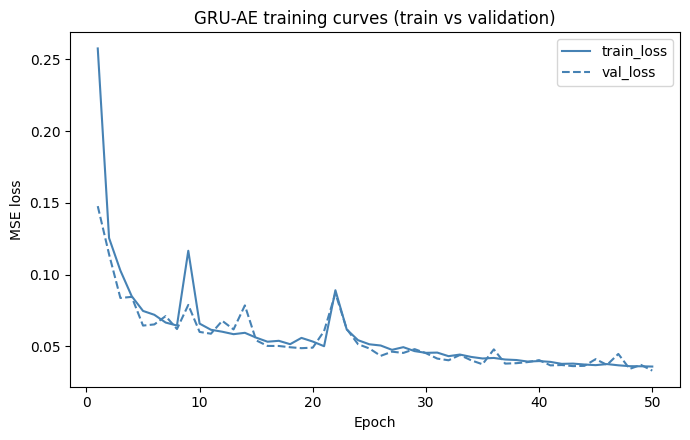

In [14]:
epochs_axis = np.arange(1, len(history) + 1)
train_loss = [h.get("train_loss", np.nan) for h in history]
val_loss   = [h["val_loss"] for h in history]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(epochs_axis, train_loss, label="train_loss", color="steelblue")
ax.plot(epochs_axis, val_loss, label="val_loss", color="steelblue", linestyle="--")
ax.set_title("GRU-AE training curves (train vs validation)")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE loss")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Validation reconstruction scores

Reconstruction error on the known-only validation windows (no novel windows). Only descriptive statistics are reported, as a sanity check that normal data is reconstructed well. No threshold is derived from them: the operating thresholds, **Threshold 1** (ROC / Youden's J) and **Threshold 2** (F1-optimal), are computed on labeled test data in sections 13 and 15.

In [15]:
val_scores = compute_scores(model, val_loader)

print("Validation reconstruction scores (known-only windows, no positive windows):")
print(f"  n windows = {len(val_scores)}")
print(f"  mean = {val_scores.mean():.6f}")
print(f"  std  = {val_scores.std():.6f}")
print(f"  min  = {val_scores.min():.6f}")
print(f"  max  = {val_scores.max():.6f}")

np.save(f"{OUTPUT_DIR}/val_scores.npy", val_scores)

Validation reconstruction scores (known-only windows, no positive windows):
  n windows = 183594
  mean = 0.033000
  std  = 0.195084
  min  = 0.000040
  max  = 11.326316


## 12. Progressive test: reconstruction scores and labels per novel appliance

For each difficulty level (low and high power), build the known + novel aggregate, score every window, and label it 1 if the novel appliance was ON in that window. We report ROC-AUC, PR-AUC and the best-F1 operating point per appliance, and collect `(scores, labels)` for the pooled thresholds below.

In [17]:
def scores_for_aggregate(model, scaler, aggregate_values):
    scaled = scaler.transform(aggregate_values)
    windows = make_windows(scaled, WINDOW_SIZE, STEP)
    ds = TensorDataset(torch.tensor(windows, dtype=torch.float32))
    loader = DeviceDataLoader(DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False), device)
    return compute_scores(model, loader), windows.shape[0]


def run_progressive_test(model, scaler, dataset):
    """
    Builds, for each power level, the (scores, labels) pair needed to compute
    ROC-AUC / PR-AUC and, later, ROC-based thresholds. No anomaly decision here.
    """
    data = {}
    for level, appliance_name in NEW_APPLIANCE_LEVELS.items():
        df_known = build_synthetic_aggregate(
            dataset, BUILDING, KNOWN_APPLIANCES, SAMPLE_PERIOD,
            start=TEST_START, end=TEST_END,
        )
        novel = load_appliance_power(
            dataset, BUILDING, appliance_name, SAMPLE_PERIOD,
            start=TEST_START, end=TEST_END,
        )
        novel = novel.reindex(df_known.index).fillna(0.0)
        combined_aggregate = (df_known["aggregate"].values + novel.values).astype(np.float32)

        scores, n_windows = scores_for_aggregate(model, scaler, combined_aggregate)

        thr_appl = ON_THRESHOLDS.get(appliance_name, 15)
        labels = make_window_labels(novel.values, thr_appl, WINDOW_SIZE, STEP)

        n = min(len(scores), len(labels))
        scores_n, labels_n = scores[:n], labels[:n]

        if labels_n.sum() == 0 or labels_n.sum() == len(labels_n):
            print(f"[{level}] '{appliance_name}': degenerate labels (all-0 or all-1) -- "
                  f"widen the test period or check the ON threshold.")
            continue

        roc = roc_auc_score(labels_n, scores_n)
        pr = average_precision_score(labels_n, scores_n)

        # --- Best-F1 operating point for this appliance (precision / recall / F1) ---
        precision_curve, recall_curve, pr_thresholds = precision_recall_curve(labels_n, scores_n)
        precision_curve, recall_curve = precision_curve[:-1], recall_curve[:-1]
        denom = precision_curve + recall_curve
        f1_curve = np.divide(2 * precision_curve * recall_curve, denom,
                              out=np.zeros_like(denom), where=denom > 0)
        best_idx = np.argmax(f1_curve)
        best_threshold = pr_thresholds[best_idx]
        best_precision = precision_curve[best_idx]
        best_recall = recall_curve[best_idx]
        best_f1 = f1_curve[best_idx]

        data[level] = {
            "appliance": appliance_name,
            "scores": scores_n,
            "labels": labels_n,
            "roc_auc": roc,
            "pr_auc": pr,
            "n_windows": n,
            "n_positive": int(labels_n.sum()),
            "best_threshold": best_threshold,
            "precision": best_precision,
            "recall": best_recall,
            "f1_score": best_f1,
        }
        print(f"[{level:6s}] {appliance_name:20s} ROC-AUC={roc:.3f}  PR-AUC={pr:.3f}  "
              f"(n={n}, positives={int(labels_n.sum())})")
        print(f"           best-F1 threshold={best_threshold:.6f}  "
              f"Precision={best_precision:.3f}  Recall={best_recall:.3f}  F1={best_f1:.3f}")
    return data


progressive_data = run_progressive_test(model, scaler, dataset)

[low   ] microwave            ROC-AUC=0.978  PR-AUC=0.659  (n=175641, positives=11073)
           best-F1 threshold=0.258505  Precision=0.651  Recall=0.761  F1=0.701
[high  ] kettle               ROC-AUC=0.985  PR-AUC=0.763  (n=175641, positives=10159)
           best-F1 threshold=0.396203  Precision=0.739  Recall=0.803  F1=0.770


## 13. Threshold 1: ROC / Youden's J

Following the USAD paper, the threshold is the point of the ROC curve maximizing `TPR - FPR` (Youden's J), computed on the labeled test windows of all novel-appliance levels pooled together (`1` = novel appliance present, `0` = known-only). Because it is selected on labeled test data, the resulting operating-point metrics are optimistic (see the limitations at the end).

In [18]:
def usad_roc_threshold(y_test, y_pred):
    """
    USAD-style threshold selection: the point on the ROC curve that maximizes
    (TPR - FPR), i.e. Youden's J statistic.
    y_test: binary ground-truth labels (1 = anomaly / novel appliance present)
    y_pred: continuous anomaly scores (reconstruction error)
    Returns: threshold, fpr_at_threshold, tpr_at_threshold, auc
    """
    fpr, tpr, thresholds = roc_curve(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred)
    idx = np.argmax(tpr - fpr)
    return thresholds[idx], fpr[idx], tpr[idx], auc


# Pool all levels together to get one global operating threshold (Threshold 1)
y_test_all = np.concatenate([d["labels"] for d in progressive_data.values()])
y_pred_all = np.concatenate([d["scores"] for d in progressive_data.values()])

THRESHOLD1, fpr1, tpr1, auc1 = usad_roc_threshold(y_test_all, y_pred_all)

print(f"Threshold 1 (ROC / Youden's J, pooled across levels) = {THRESHOLD1:.6f}")
print(f"  at this threshold -> FPR={fpr1:.3f}  TPR={tpr1:.3f}  (pooled AUC={auc1:.3f})")

Threshold 1 (ROC / Youden's J, pooled across levels) = 0.022000
  at this threshold -> FPR=0.098  TPR=0.995  (pooled AUC=0.981)


## 14. ROC curve with Threshold 1

Pooled ROC curve over the novel-appliance levels, with the Youden's J operating point (Threshold 1) marked.

In [ ]:
fpr_curve, tpr_curve, thr_curve = roc_curve(y_test_all, y_pred_all)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr_curve, tpr_curve, color="darkorange", linewidth=2, label=f"ROC (AUC = {auc1:.3f})")
ax.plot([0, 1], [0, 1], color="gray", linestyle="--", linewidth=1, label="Chance (AUC = 0.5)")

ax.scatter([fpr1], [tpr1], color="crimson", zorder=5, s=90,
           label=f"Threshold 1 = {THRESHOLD1:.6f}\n(FPR={fpr1:.3f}, TPR={tpr1:.3f})")
ax.annotate(f"threshold = {THRESHOLD1:.6f}",
            xy=(fpr1, tpr1), xytext=(min(fpr1 + 0.12, 0.65), max(tpr1 - 0.15, 0.05)),
            arrowprops=dict(arrowstyle="->", color="crimson"))

ax.set_xlabel("False positive rate (FPR)")
ax.set_ylabel("True positive rate (TPR)")
ax.set_title("Pooled ROC curve and operating threshold (Threshold 1, Youden's J)")
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.0])
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 15. Threshold 2: F1-optimal

As an alternative to Youden's J, pick the threshold maximizing the **F1-score** on the precision-recall curve, using the same pooled labeled test data (`y_test_all`, `y_pred_all`). We report the same metrics as for Threshold 1 plus the F1-score, so the two selection rules can be compared directly.

In [20]:
def usad_f1_threshold(y_test, y_pred):
    """
    F1-optimal threshold selection: the point on the precision-recall curve that
    maximizes the F1-score.
    y_test: binary ground-truth labels (1 = anomaly / novel appliance present)
    y_pred: continuous anomaly scores (reconstruction error)
    Returns: threshold, fpr_at_threshold, tpr_at_threshold, auc, best_f1
    """
    precision, recall, thresholds = precision_recall_curve(y_test, y_pred)
    # precision_recall_curve returns len(thresholds) == len(precision) - 1;
    # the last (precision, recall) point has no associated threshold, drop it.
    precision, recall = precision[:-1], recall[:-1]

    denom = precision + recall
    f1_scores = np.divide(2 * precision * recall, denom,
                           out=np.zeros_like(denom), where=denom > 0)

    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx]
    best_f1 = f1_scores[best_idx]

    decisions = (y_pred > best_threshold).astype(int)
    tp = np.sum((decisions == 1) & (y_test == 1))
    fp = np.sum((decisions == 1) & (y_test == 0))
    tn = np.sum((decisions == 0) & (y_test == 0))
    fn = np.sum((decisions == 0) & (y_test == 1))
    fpr = fp / (fp + tn) if (fp + tn) > 0 else float("nan")
    tpr = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
    auc = roc_auc_score(y_test, y_pred)
    return best_threshold, fpr, tpr, auc, best_f1


THRESHOLD2, fpr2, tpr2, auc2, f1_2 = usad_f1_threshold(y_test_all, y_pred_all)

print(f"Threshold 2 (F1-optimal, pooled across levels) = {THRESHOLD2:.6f}")
print(f"  at this threshold -> FPR={fpr2:.3f}  TPR={tpr2:.3f}  F1={f1_2:.3f}  (pooled AUC={auc2:.3f})")

print()
print("Comparison -- Threshold 1 (ROC / Youden\'s J) vs Threshold 2 (F1-optimal):")
print(f"  Threshold 1: thr={THRESHOLD1:.6f}  FPR={fpr1:.3f}  TPR={tpr1:.3f}  AUC={auc1:.3f}")
print(f"  Threshold 2: thr={THRESHOLD2:.6f}  FPR={fpr2:.3f}  TPR={tpr2:.3f}  AUC={auc2:.3f}  F1={f1_2:.3f}")

Threshold 2 (F1-optimal, pooled across levels) = 0.267318
  at this threshold -> FPR=0.026  TPR=0.808  F1=0.730  (pooled AUC=0.981)

Comparison -- Threshold 1 (ROC / Youden's J) vs Threshold 2 (F1-optimal):
  Threshold 1: thr=0.022000  FPR=0.098  TPR=0.995  AUC=0.981
  Threshold 2: thr=0.267318  FPR=0.026  TPR=0.808  AUC=0.981  F1=0.730


## 16. Precision-recall curve with Threshold 2

Pooled precision-recall curve with the F1-optimal operating point (Threshold 2) marked.

In [ ]:
precision_curve, recall_curve, pr_thresholds = precision_recall_curve(y_test_all, y_pred_all)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(recall_curve, precision_curve, color="seagreen", linewidth=2,
        label=f"Precision-Recall (ROC-AUC={auc2:.3f})")

# Precision at the recall achieved by Threshold 2 (tpr2 == recall at that operating point)
precision_at_thr2 = f1_2 * tpr2 / (2 * tpr2 - f1_2) if (2 * tpr2 - f1_2) != 0 else np.nan

ax.scatter([tpr2], [precision_at_thr2], color="crimson", zorder=5, s=90,
           label=f"Threshold 2 = {THRESHOLD2:.6f}\n(Recall={tpr2:.3f}, F1={f1_2:.3f})")

ax.set_xlabel("Recall (TPR)")
ax.set_ylabel("Precision")
ax.set_title("Pooled precision-recall curve and operating threshold (Threshold 2, F1-optimal)")
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 17. Sequential test by period (no novel / low power / high power)

The test period (`TEST_START` to `TEST_END`) is split into **3 equal sub-periods**:

- **Period 1**: known aggregate only, no novel appliance (the "normal" reference).
- **Period 2**: plus a **low-power** appliance (`NEW_APPLIANCE_LEVELS['low']`).
- **Period 3**: plus a **high-power** appliance (`NEW_APPLIANCE_LEVELS['high']`).

For each sliding window we compute the **anomaly score** (USAD reconstruction error) and the model **decision** (`normal` if score <= threshold, `anomaly` otherwise), using the operating threshold `THRESHOLD` chosen in the first lines of the next cell.

In [ ]:
# Operating threshold used for every decision below:
# THRESHOLD1 = ROC / Youden's J, THRESHOLD2 = F1-optimal (default).
THRESHOLD = THRESHOLD2


def split_into_n_periods(start, end, n):
    """Split [start, end] into n contiguous sub-periods of equal duration."""
    bounds = pd.date_range(start=start, end=end, periods=n + 1)
    return [(bounds[i].strftime("%Y-%m-%d %H:%M:%S"), bounds[i + 1].strftime("%Y-%m-%d %H:%M:%S"))
            for i in range(n)]


def fpr_fnr_scores(labels, decisions):
    """False-positive rate (FPR) and false-negative rate (FNR) over windows.

    FPR = FP / (FP + TN): among truly normal windows (label 0), the share flagged as anomalies.
    It is the relevant metric when a period has no real positives: F1 is undefined there,
    but a good model should still keep the FPR close to 0.

    FNR = FN / (FN + TP): among truly anomalous windows (label 1), the share missed by the model.
    """
    labels = np.asarray(labels)
    decisions = np.asarray(decisions)
    neg_mask = (labels == 0)
    pos_mask = (labels == 1)
    fpr = float(((decisions == 1) & neg_mask).sum() / neg_mask.sum()) if neg_mask.sum() > 0 else float("nan")
    fnr = float(((decisions == 0) & pos_mask).sum() / pos_mask.sum()) if pos_mask.sum() > 0 else float("nan")
    return fpr, fnr


period_bounds = split_into_n_periods(TEST_START, TEST_END, 3)

period_labels = [
    "P1 - no novel appliance",
    f"P2 - + {NEW_APPLIANCE_LEVELS['low']} (low power)",
    f"P3 - + {NEW_APPLIANCE_LEVELS['high']} (high power)",
]
period_appliance = [None, NEW_APPLIANCE_LEVELS['low'], NEW_APPLIANCE_LEVELS['high']]

sequential_results = []
all_scores, all_decisions, period_boundaries_idx = [], [], [0]

for (p_start, p_end), label, appliance_name in zip(period_bounds, period_labels, period_appliance):
    # Known-appliance aggregate over this sub-period (raw signal, in Watts)
    df_known = build_synthetic_aggregate(
        dataset, BUILDING, KNOWN_APPLIANCES, SAMPLE_PERIOD,
        start=p_start, end=p_end,
    )
    aggregate_values = df_known["aggregate"].values.astype(np.float32)

    # Inject the novel appliance matching the power level of this period
    novel = None
    if appliance_name is not None:
        novel = load_appliance_power(dataset, BUILDING, appliance_name, SAMPLE_PERIOD, start=p_start, end=p_end)
        novel = novel.reindex(df_known.index).fillna(0.0)
        aggregate_values = aggregate_values + novel.values.astype(np.float32)

    # USAD reconstruction score per window + decision against the operating threshold
    scores, n_windows = scores_for_aggregate(model, scaler, aggregate_values)
    decisions = (scores > THRESHOLD).astype(int)

    # Ground truth per window: 1 if the novel appliance is ON within the window, else 0.
    # Period 1 (no injected appliance): every window is "normal" (0).
    if appliance_name is None:
        labels = np.zeros(n_windows, dtype=int)
    else:
        thr_appl = ON_THRESHOLDS.get(appliance_name, 15)
        labels = make_window_labels(novel.values, thr_appl, WINDOW_SIZE, STEP)

    n_common = min(n_windows, len(labels))
    scores_c, decisions_c, labels_c = scores[:n_common], decisions[:n_common], labels[:n_common]

    n_anom = int(decisions.sum())
    pct_anom = 100.0 * n_anom / max(n_windows, 1)

    has_positives = labels_c.sum() > 0
    # F1 needs real positives to be defined (recall = TP / (TP + FN) is undefined if TP + FN = 0).
    # With no real positive in the period (P1), F1 and FNR are marked N/A and the FPR is the
    # metric of interest: does the model raise false alarms on normal data?
    f1 = f1_score(labels_c, decisions_c, zero_division=0) if has_positives else float("nan")
    acc = accuracy_score(labels_c, decisions_c)
    fpr, fnr = fpr_fnr_scores(labels_c, decisions_c)

    sequential_results.append({
        "label": label, "appliance": appliance_name, "start": p_start, "end": p_end,
        "n_windows": n_windows, "scores": scores, "decisions": decisions, "labels": labels,
        "aggregate_values": aggregate_values,
        "n_anomalies": n_anom, "pct_anomalies": pct_anom,
        "f1_score": f1, "accuracy": acc, "fpr": fpr, "fnr": fnr, "has_positives": has_positives,
    })

    all_scores.append(scores)
    all_decisions.append(decisions)
    period_boundaries_idx.append(period_boundaries_idx[-1] + n_windows)

    f1_str = f"{f1:.3f}" if has_positives else "N/A (no real positives)"
    fnr_str = f"{fnr:.3f}" if has_positives else "N/A (no real positives)"
    print(f"{label:45s} | windows={n_windows:7d} | F1={f1_str:22s} | accuracy={acc:.3f} | "
          f"FPR={fpr:.3f} | FNR={fnr_str:22s} | threshold={THRESHOLD:.6f} | "
          f"detected anomalies={n_anom:7d} ({pct_anom:5.1f}%)")

all_scores_concat = np.concatenate(all_scores)
all_decisions_concat = np.concatenate(all_decisions)

# Summary table
summary_df = pd.DataFrame([
    {
        "period": r["label"],
        "injected_appliance": r["appliance"] if r["appliance"] else "-",
        "start": r["start"], "end": r["end"],
        "n_windows": r["n_windows"],
        "f1_score": (round(r["f1_score"], 3) if r["has_positives"] else "N/A"),
        "accuracy": round(r["accuracy"], 3),
        "fpr": round(r["fpr"], 3) if not np.isnan(r["fpr"]) else "N/A",
        "fnr": (round(r["fnr"], 3) if r["has_positives"] else "N/A"),
        "threshold": THRESHOLD, "n_anomalies": r["n_anomalies"],
        "%_anomalies": round(r["pct_anomalies"], 1),
    }
    for r in sequential_results
])
summary_df

## 18. Anomaly detection per period on the denormalized signal

For each period, the **real aggregate signal (in Watts)** is plotted, with the zones where the model **detected an anomaly** (decision = 1 against `THRESHOLD`) shaded in red. The y-axis is hidden on purpose: what matters here is *when* the model detects an anomaly, not the absolute amplitude, which varies widely between a period without a novel appliance and one with, say, a 2000 W kettle.

The title of each panel shows the **F1-score**, **accuracy**, **FPR** and **FNR** computed against the ground truth (is the novel appliance really ON in the window?).

In [ ]:
def contiguous_true_runs(mask):
    """Return the list of [start, end) intervals where `mask` is continuously True."""
    runs = []
    start = None
    for i, v in enumerate(mask):
        if v and start is None:
            start = i
        elif not v and start is not None:
            runs.append((start, i))
            start = None
    if start is not None:
        runs.append((start, len(mask)))
    return runs


fig, axes = plt.subplots(len(sequential_results), 1, figsize=(14, 12), sharex=False)

for ax, r in zip(axes, sequential_results):
    signal = r["aggregate_values"]   # real signal, in Watts (denormalized)
    decisions = r["decisions"]
    x_signal = np.arange(len(signal))

    ax.plot(x_signal, signal, color="steelblue", linewidth=0.6)

    # Zones where the model detects an anomaly (windows with decision = 1).
    # Window j covers samples [j * STEP, j * STEP + WINDOW_SIZE), so window indices
    # are converted back to sample indices before shading.
    for start, end in contiguous_true_runs(decisions == 1):
        ax.axvspan(start * STEP, (end - 1) * STEP + WINDOW_SIZE, color="crimson", alpha=0.25, lw=0)

    ax.get_yaxis().set_visible(False)
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    f1_str = f"{r['f1_score']:.3f}" if r["has_positives"] else "N/A"
    fnr_str = f"{r['fnr']:.3f}" if r["has_positives"] else "N/A"
    ax.set_title(
        f"{r['label']}  |  F1-score={f1_str}  |  accuracy={r['accuracy']:.3f}  |  FPR={r['fpr']:.3f}  |  FNR={fnr_str}",
        fontsize=10, loc="left",
    )

axes[-1].set_xlabel("Sample index (denormalized signal, in Watts)")

legend_elems = [
    Patch(facecolor="steelblue", label="Aggregate power (Watts)"),
    Patch(facecolor="crimson", alpha=0.25, label="Zone detected as anomaly"),
]
fig.legend(handles=legend_elems, loc="upper right", ncol=2, bbox_to_anchor=(0.98, 1.02))

fig.suptitle("Anomaly detection per period on the denormalized signal (y-axis hidden)", y=1.0)
plt.tight_layout()
plt.show()

## 19. Diagnostics per period: score and novel-appliance state

For a zoomed range of windows (`ZOOM_START`, `ZOOM_LENGTH`; edit them to move around the signal), each period shows two aligned panels: the anomaly score (the per-window reconstruction MSE) with the threshold and the windows flagged as anomalies, and the ON/OFF state of the injected appliance (1 = ON at some point in the window).

In [ ]:
ZOOM_START = 800       # index of the first displayed window
ZOOM_LENGTH = 300   # number of displayed windows

fig = plt.figure(figsize=(14, 3.6 * len(sequential_results)))
gs = fig.add_gridspec(len(sequential_results) * 2, 1,
                      height_ratios=[3, 1] * len(sequential_results), hspace=0.55)

for i, r in enumerate(sequential_results):
    scores, decisions, labels = r["scores"], r["decisions"], r["labels"]
    n = len(scores)
    zs = max(0, min(ZOOM_START, n - 1))
    ze = min(n, zs + ZOOM_LENGTH)
    x = np.arange(zs, ze)

    scores_z, decisions_z, labels_z = scores[zs:ze], decisions[zs:ze], labels[zs:ze]

    ax_score = fig.add_subplot(gs[2 * i, 0])
    ax_onoff = fig.add_subplot(gs[2 * i + 1, 0], sharex=ax_score)

    # --- Anomaly score (top): the score is the per-window reconstruction MSE ---
    ax_score.plot(x, scores_z, color="steelblue", linewidth=1.0, label="Anomaly score (reconstruction MSE)")
    anom_mask = decisions_z == 1
    ax_score.scatter(x[anom_mask], scores_z[anom_mask], color="crimson", s=10, zorder=5,
                     label="Detected as novel appliance")
    ax_score.axhline(THRESHOLD, color="black", linestyle="--", linewidth=1.2,
                     label=f"Threshold = {THRESHOLD:.6f}")

    # Precision / recall are computed over the whole period (full labels and decisions,
    # not the zoomed range), consistent with the F1 / accuracy / FPR / FNR shown.
    precision_val = precision_score(labels, decisions, zero_division=0) if r["has_positives"] else float("nan")
    recall_val = recall_score(labels, decisions, zero_division=0) if r["has_positives"] else float("nan")

    f1_str = f"{r['f1_score']:.3f}" if r["has_positives"] else "N/A"
    fnr_str = f"{r['fnr']:.3f}" if r["has_positives"] else "N/A"
    precision_str = f"{precision_val:.3f}" if r["has_positives"] else "N/A"
    recall_str = f"{recall_val:.3f}" if r["has_positives"] else "N/A"
    ax_score.set_title(
        f"{r['label']}  (windows {zs}-{ze})  |  F1={f1_str}  Precision={precision_str}  "
        f"Recall={recall_str}  accuracy={r['accuracy']:.3f}  FPR={r['fpr']:.3f}  FNR={fnr_str}",
        fontsize=10, loc="left",
    )
    ax_score.set_ylabel("Score")
    plt.setp(ax_score.get_xticklabels(), visible=False)
    if i == 0:
        ax_score.legend(loc="upper right", fontsize=8, ncol=3)

    # --- Injected appliance ON/OFF (bottom) ---
    # labels_z is 1 if the injected appliance is ON at least once within the window.
    ax_onoff.step(x, labels_z, where="post", color="darkorange", linewidth=1.2)
    ax_onoff.fill_between(x, 0, labels_z, step="post", color="darkorange", alpha=0.25)
    ax_onoff.set_ylim(-0.15, 1.15)
    ax_onoff.set_yticks([0, 1])
    ax_onoff.set_yticklabels(["OFF", "ON"])
    ax_onoff.set_ylabel("Appliance")
    if i == len(sequential_results) - 1:
        ax_onoff.set_xlabel("Window index")

plt.tight_layout()
plt.show()

## 20. Input versus reconstruction per period

For a zoomed range of windows, compare the input signal with the signal reconstructed by the model, at the **last time step of each window**, converted back to Watts.

In [ ]:
RECON_ZOOM_LENGTH = 100
RECON_ZOOM_START = 870

def reconstructions_for_aggregate(model, scaler, aggregate_values):
    """For each window, returns the input value and the model's reconstruction, at the
    last time-step of the window (convention 'lastv'), in Watts (denormalized)."""
    scaled = scaler.transform(aggregate_values)
    windows = make_windows(scaled, WINDOW_SIZE, STEP)
    ds = TensorDataset(torch.tensor(windows, dtype=torch.float32))
    loader = DeviceDataLoader(DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False), device)

    model.eval()
    input_last, recon_last = [], []
    with torch.no_grad():
        for [batch] in loader:
            batch = to_device(batch, device)
            recon = model(batch)
            input_last.append(batch[:, -1].cpu().numpy())
            recon_last.append(recon[:, -1].cpu().numpy())

    input_last = np.concatenate(input_last) if input_last else np.empty((0,))
    recon_last = np.concatenate(recon_last) if recon_last else np.empty((0,))

    input_last_w = scaler.inverse_transform(input_last)
    recon_last_w = scaler.inverse_transform(recon_last)
    return input_last_w, recon_last_w


fig, axes = plt.subplots(len(sequential_results), 1,
                          figsize=(14, 3.2 * len(sequential_results)), sharex=False)
if len(sequential_results) == 1:
    axes = [axes]

for ax, r in zip(axes, sequential_results):
    input_w, recon_w = reconstructions_for_aggregate(model, scaler, r["aggregate_values"])
    n = len(input_w)
    zs = max(0, min(RECON_ZOOM_START, n - 1))
    ze = min(n, zs + RECON_ZOOM_LENGTH)
    x = np.arange(zs, ze)

    ax.plot(x, input_w[zs:ze], color="steelblue", linewidth=1.0, label="Input (real signal, Watts)")
    ax.plot(x, recon_w[zs:ze], color="teal", linewidth=1.0, alpha=0.85, label="GRU-AE reconstruction (Watts)")

    ax.set_title(f"{r['label']}  (windows {zs}-{ze})", fontsize=10, loc="left")
    ax.set_ylabel("Power (W)")
    ax.legend(loc="upper right", fontsize=8, ncol=2)

axes[-1].set_xlabel("Window index")
fig.suptitle("Input signal vs GRU-AE reconstruction, by period (last time-step of each window)")
plt.tight_layout()
plt.show()

## Results and limitations

**Results of the reference run** (values printed by the cells above; a re-run can differ slightly because of GPU non-determinism):

| Novel appliance | Level | ROC-AUC | PR-AUC | Positive windows |
|---|---|---|---|---|
| microwave | low power | 0.978 | 0.659 | about 6% |
| kettle | high power | 0.985 | 0.763 | about 6% |

Pooled over both levels, ROC-AUC is 0.981. At the two operating thresholds selected on the pooled test data:

| Threshold | FPR | TPR | F1 |
|---|---|---|---|
| Threshold 1 (Youden's J) | 0.098 | 0.995 | - |
| Threshold 2 (F1-optimal) | 0.026 | 0.808 | 0.730 |


**Limitations** (to keep in mind before reusing these numbers):

- **Thresholds are chosen on labeled test data.** ROC-AUC and PR-AUC do not depend on a threshold, but the FPR, TPR, F1 and accuracy at Threshold 1 and Threshold 2 are optimistic. A cleaner protocol would select the threshold on a separate labeled validation period.
- **Validation windows overlap training windows.** The train/validation split is a random permutation of heavily overlapping sliding windows (200 samples with a stride of 5), so the validation loss is not an independent estimate of generalization.
- **Narrow setting.** One house (House 1), a synthetic aggregate built from three known appliances, and only two novel appliances. The ON thresholds used to label windows are hand-chosen.
- **Single run.** One training run with one seed per model, so small differences between models (about 0.01 ROC-AUC) may not be significant.
- **PR-AUC is modest** because only about 6% of test windows are positive; the PR curve should be read against that base rate.